# Exploratory Data Analysis

Answers the core workload questions directly relevant to forecasting:
1. **Target dynamics & autocorrelation** (stationarity, memory depth)
2. **Active VM count & churn verification** (fleet size over time)
3. **Category workload patterns** (sub-fleet dynamics)
4. **Resource tier patterns** (vCPU vs CPU load)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TRAIN_OBS = 110

meta = pd.read_csv('../challenge_data/vm_metadata.csv')
cpu  = pd.read_csv('../challenge_data/vm_cpu_readings.csv')

# Attach category and vCPU info to each reading
cpu = cpu.merge(meta[['vm_id', 'vm_category', 'virtual_core_bucket']], on='vm_id', how='left')

# Build aggregate targets
targets = cpu.groupby('timestamp').agg(
    active_vm_count=('vm_id', 'nunique'),
    aggregate_cpu_utilization=('avg_cpu', 'mean')
).reset_index().sort_values('timestamp').reset_index(drop=True)
targets['hour'] = targets['timestamp'] / 3600
train = targets.iloc[:TRAIN_OBS]

print(f'Loaded {len(meta):,} VMs, {len(cpu):,} readings, {len(targets)} timestamps')


Loaded 10,000 VMs, 1,340,000 readings, 134 timestamps


---
## 1. Targets, Churn & Autocorrelation

- **`active_vm_count`**: Constant at 10,000 for every single timestamp (no churn during trace).
- **`aggregate_cpu_utilization`**: Narrow band (9.1%?9.6%), mean ~9.35%. No 24-h seasonality in an 11.1-h window, but strong short-term autocorrelation that decays by lag 12.

Min/max readings per VM: 134 134
active_vm_count is always: [10000]


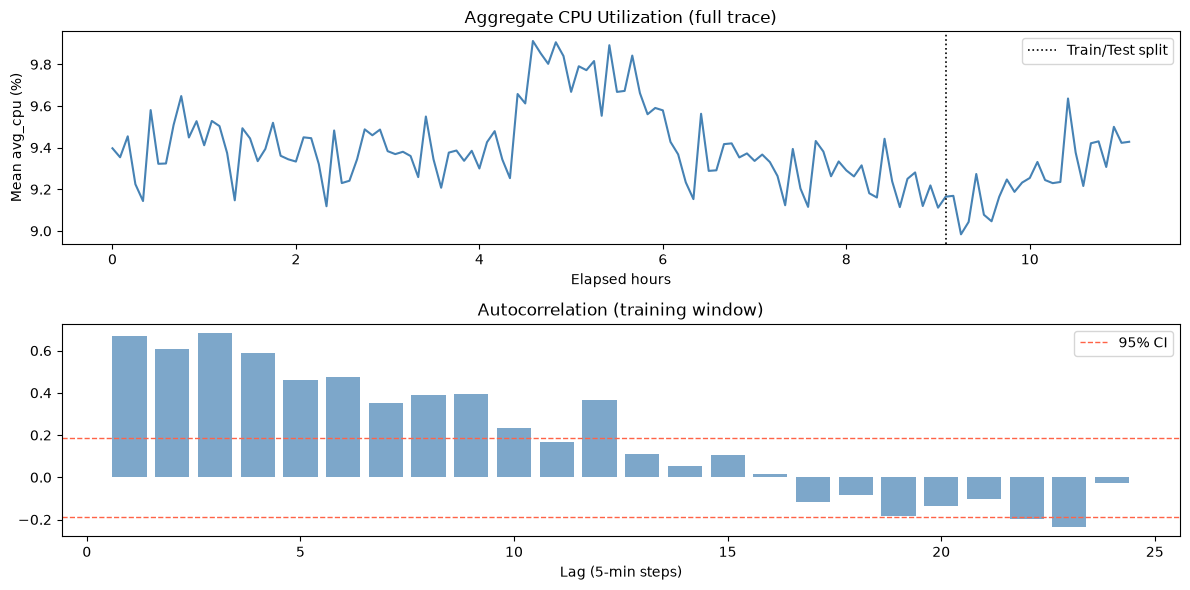

In [2]:
# Verify no churn: every VM has exactly 134 readings
readings_per_vm = cpu.groupby('vm_id').size()
print('Min/max readings per VM:', readings_per_vm.min(), readings_per_vm.max())
print('active_vm_count is always:', targets['active_vm_count'].unique())

# Plot aggregate CPU + autocorrelation
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6))

ax1.plot(targets['hour'], targets['aggregate_cpu_utilization'], color='steelblue', lw=1.5)
ax1.axvline(train['hour'].iloc[-1], color='black', ls=':', lw=1.2, label='Train/Test split')
ax1.set_title('Aggregate CPU Utilization (full trace)')
ax1.set_ylabel('Mean avg_cpu (%)')
ax1.set_xlabel('Elapsed hours')
ax1.legend()

# Autocorrelation up to lag 24
series = train['aggregate_cpu_utilization'].values
lags = range(1, 25)
acf = [np.corrcoef(series[:-k], series[k:])[0, 1] for k in lags]
ci = 1.96 / np.sqrt(len(series))
ax2.bar(list(lags), acf, color='steelblue', alpha=0.7)
ax2.axhline(ci,  color='tomato', ls='--', lw=1, label=f'95% CI')
ax2.axhline(-ci, color='tomato', ls='--', lw=1)
ax2.set_title('Autocorrelation (training window)')
ax2.set_xlabel('Lag (5-min steps)')
ax2.legend()

plt.tight_layout()
plt.show()


---
## 2. Category Differences

- **`Delay-insensitive`**: ~67% of fleet; runs at ~11.5% CPU and dictates aggregate load (r > 0.94).
- **`Interactive`**: ~20% of fleet; runs low (~3.5%) with higher relative volatility.
- **`Unknown`**: ~13% of fleet; runs low (~4.5%).

Directly informs using category-level CPU time series as predictive features.

VM counts by category:
vm_category
Delay-insensitive    6180
Interactive          3091
Unknown               729
Name: count, dtype: int64


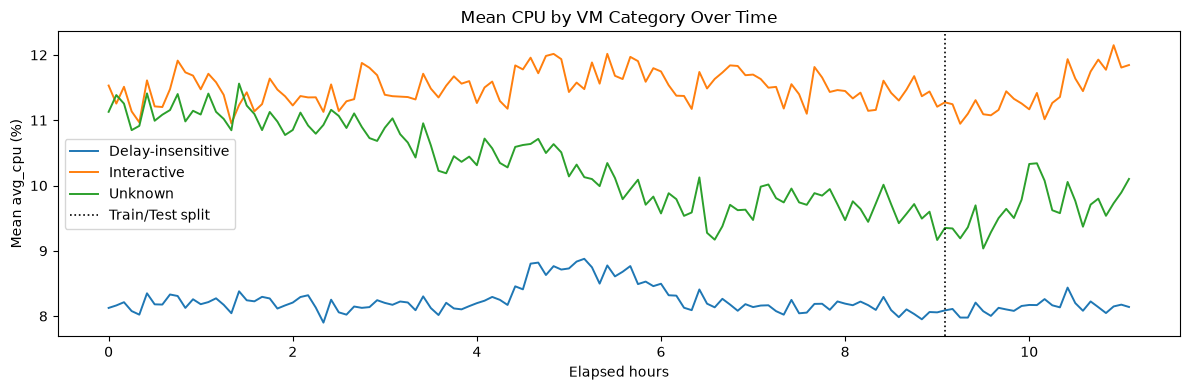

In [3]:
# VM category breakdown
cat_counts = meta['vm_category'].value_counts()
print('VM counts by category:')
print(cat_counts)

# Mean CPU over time per category
cat_ts = cpu.groupby(['timestamp', 'vm_category'])['avg_cpu'].mean().reset_index()
cat_ts['hour'] = cat_ts['timestamp'] / 3600

fig, ax = plt.subplots(figsize=(12, 4))
for cat, grp in cat_ts.groupby('vm_category'):
    ax.plot(grp['hour'], grp['avg_cpu'], label=cat, lw=1.4)
ax.axvline(train['hour'].iloc[-1], color='black', ls=':', lw=1.2, label='Train/Test split')
ax.set_title('Mean CPU by VM Category Over Time')
ax.set_ylabel('Mean avg_cpu (%)')
ax.set_xlabel('Elapsed hours')
ax.legend()
plt.tight_layout()
plt.show()


---
## 3. Resource Tier Differences (vCPU)

- Larger vCPU VMs (8, 24, >24) run at higher CPU utilization than smaller VMs (2, 4 cores).
- Motivates using core-weighted CPU as a feature rather than just raw mean CPU.
- (Memory tiers showed no meaningful variation and are dropped as uninformative).

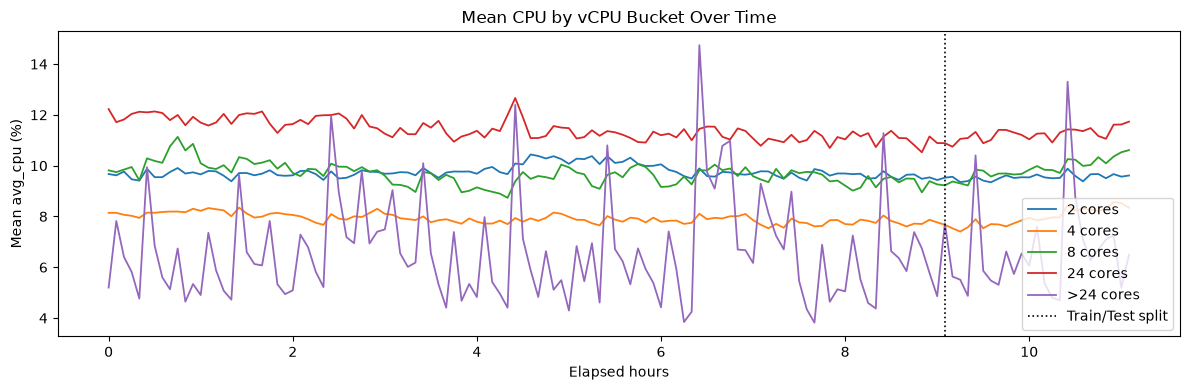

In [4]:
# Mean CPU over time per vCPU bucket
core_order = ['2', '4', '8', '24', '>24']
core_ts = cpu.groupby(['timestamp', 'virtual_core_bucket'])['avg_cpu'].mean().reset_index()
core_ts['hour'] = core_ts['timestamp'] / 3600

fig, ax = plt.subplots(figsize=(12, 4))
for tier in core_order:
    grp = core_ts[core_ts['virtual_core_bucket'] == tier]
    if not grp.empty:
        ax.plot(grp['hour'], grp['avg_cpu'], label=f'{tier} cores', lw=1.3)
ax.axvline(train['hour'].iloc[-1], color='black', ls=':', lw=1.2, label='Train/Test split')
ax.set_title('Mean CPU by vCPU Bucket Over Time')
ax.set_ylabel('Mean avg_cpu (%)')
ax.set_xlabel('Elapsed hours')
ax.legend()
plt.tight_layout()
plt.show()
